### MIRA FINAL PROJECT: Malka Salvador, Míriam Culleré and Mònica Veenhoven

#### 1. Configuration and Set-up
Select the cases to register in CASES[ ] !


In [44]:
# --- IMPORTS ---
import SimpleITK as sitk
import numpy as np
import os

# --- CONFIGURATION ---
CASES = ['copd1', 'copd2', 'copd3', 'copd4','copd7', 'copd10'] #['copd10']# ['copd7', 'copd9']#['copd1', 'copd2', 'copd3', 'copd4']  <-------- SELECT CASES HERE <------------------

BASE_PATH = os.getcwd()      # Current working directory
PREPROCESSED_DIR = "preprocessed_for_registration"  # Folder for preprocessed images
MASKS_DIR = "lung_masks1"    # Folder for lung masks


##### 1.1 CONVERT FILES TO NIFTI. 
Select the cases you want to convert in CASE_INFO. -- Make sure to download the COPD folders in the main path. !!

In [ ]:
CASE_INFO = {                                                                 # <---  ### SELECT CASES HERE ###
    #'copd1': {'dim': (512, 512, 121), 'spacing': (0.625, 0.625, 2.5)},
    #'copd2': {'dim': (512, 512, 102), 'spacing': (0.645, 0.645, 2.5)},
    #'copd3': {'dim': (512, 512, 126), 'spacing': (0.652, 0.652, 2.5)},
    #'copd4': {'dim': (512, 512, 126), 'spacing': (0.590, 0.590, 2.5)},
    # 'copd5': {'dim': (512, 512, 131), 'spacing': (0.647, 0.647, 2.5)},
    # 'copd6': {'dim': (512, 512, 119), 'spacing': (0.633, 0.633, 2.5)},
    # 'copd7': {'dim': (512, 512, 112), 'spacing': (0.625, 0.625, 2.5)},
    # 'copd8': {'dim': (512, 512, 115), 'spacing': (0.586, 0.586, 2.5)},
    # 'copd9': {'dim': (512, 512, 116), 'spacing': (0.664, 0.664, 2.5)},
    #'copd10': {'dim': (512, 512, 135), 'spacing': (0.742, 0.742, 2.5)},
}

phases = ['iBH', 'eBH']

def create_corrected_nifti():
    print("--- CREATING NIFTI (Z-AXIS FLIPPED) ---")
    
    # Direction: X=1, Y=1, Z=-1 (Fixes the orientation issue)
    corrected_direction = (1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, -1.0)
    
    for case_id, info in CASE_INFO.items():
        print(f"\nProcessing {case_id}...")
        if not os.path.isdir(case_id): continue
            
        dim = info['dim']
        spc = info['spacing']
        
        for phase in phases:
            # INPUTS
            raw_img_path = os.path.join(case_id, f"{case_id}_{phase}CT.img")
            txt_pts_path = os.path.join(case_id, f"{case_id}_300_{phase}_xyz_r1.txt")
            
            # OUTPUTS
            out_img_path = os.path.join(case_id, f"{case_id}_{phase}CT.nii.gz")
            out_msk_path = os.path.join(case_id, f"{case_id}_300_{phase}_xyz_r1.nii.gz")
            
            img_reference = None
            
            # 1. Convert IMAGE
            if os.path.exists(raw_img_path):
                with open(raw_img_path, 'rb') as f:
                    raw_buffer = f.read()
                
                img = sitk.GetImageFromArray(
                    np.frombuffer(raw_buffer, dtype=np.int16).reshape(dim[::-1])
                )
                img.SetSpacing(spc)
                img.SetOrigin((0,0,0))
                img.SetDirection(corrected_direction) # <--- Z-FLIP APPLIED HERE
                
                sitk.WriteImage(img, out_img_path)
                print(f"  [Image] Saved: {out_img_path}")
                img_reference = img
            
            # 2. Convert POINTS (Mask)
            if os.path.exists(txt_pts_path) and img_reference is not None:
                mask = sitk.Image(img_reference.GetSize(), sitk.sitkUInt8)
                mask.CopyInformation(img_reference)
                
                points_data = np.loadtxt(txt_pts_path)
                for point in points_data:
                    # 1-based -> 0-based
                    idx = (int(point[0])-1, int(point[1])-1, int(point[2])-1)
                    if (0 <= idx[0] < dim[0]) and (0 <= idx[1] < dim[1]) and (0 <= idx[2] < dim[2]):
                        mask[idx] = 1 # Single pixel
                
                # OPTIONAL: Dilate slightly just for visibility (Radius 1)
                # You can remove this line if you want single pixels
                mask = sitk.BinaryDilate(mask, [1,1,1])
                
                sitk.WriteImage(mask, out_msk_path)
                print(f"  [Points] Saved mask: {out_msk_path}")

        
if __name__ == "__main__":
    create_corrected_nifti()

--- CREATING NIFTI (Z-AXIS FLIPPED) ---

Processing copd10...
  [Image] Saved: copd10\copd10_iBHCT.nii.gz
  [Points] Saved mask: copd10\copd10_300_iBH_xyz_r1.nii.gz
  [Image] Saved: copd10\copd10_eBHCT.nii.gz


##### 1.2 CHECK THE BASELINE TRE
Select the cases to check.

In [26]:
'''---Compute the Baseline TRE---'''

CASE_INFO = {                                                                 # <---  ### SELECT CASES HERE ###
    'copd1': {'dim': (512, 512, 121), 'spacing': (0.625, 0.625, 2.5)},
    'copd2': {'dim': (512, 512, 102), 'spacing': (0.645, 0.645, 2.5)},
    'copd3': {'dim': (512, 512, 126), 'spacing': (0.652, 0.652, 2.5)},
    'copd4': {'dim': (512, 512, 126), 'spacing': (0.590, 0.590, 2.5)},
    # 'copd5': {'dim': (512, 512, 131), 'spacing': (0.647, 0.647, 2.5)},
    # 'copd6': {'dim': (512, 512, 119), 'spacing': (0.633, 0.633, 2.5)},
    #'copd7': {'dim': (512, 512, 112), 'spacing': (0.625, 0.625, 2.5)},
    # 'copd8': {'dim': (512, 512, 115), 'spacing': (0.586, 0.586, 2.5)},
    # 'copd9': {'dim': (512, 512, 116), 'spacing': (0.664, 0.664, 2.5)},
    #'copd10': {'dim': (512, 512, 135), 'spacing': (0.742, 0.742, 2.5)},
}

def compute_baseline_tre_cell(case_dict):
    print(f"{'Case':<10} | {'Mean TRE (mm)':<15} | {'Std Dev':<10} | {'Max TRE':<10}")
    print("-" * 55)
    
    for case_id, info in case_dict.items():
        # Paths for inhale (iBH) and exhale (eBH) landmarks
        path_ibh = os.path.join(case_id, f"{case_id}_300_iBH_xyz_r1.txt")
        path_ebh = os.path.join(case_id, f"{case_id}_300_eBH_xyz_r1.txt")
        
        if not os.path.exists(path_ibh) or not os.path.exists(path_ebh):
            print(f"{case_id:<10} | Missing landmark files.")
            continue
            
        # Load landmarks (1-indexed voxel coordinates)
        pts_ibh = np.loadtxt(path_ibh)
        pts_ebh = np.loadtxt(path_ebh)
        
        # Verify point counts match
        if pts_ibh.shape != pts_ebh.shape:
            print(f"{case_id:<10} | Mismatch: {len(pts_ibh)} vs {len(pts_ebh)} pts.")
            continue
            
        # Spacing vector (X, Y, Z)
        spacing = np.array(info['spacing'])
        
        # Convert to Physical Coordinates (mm)
        # Shift 1-based index to 0-based, then multiply by spacing
        pts_ibh_mm = (pts_ibh - 1) * spacing
        pts_ebh_mm = (pts_ebh - 1) * spacing
        
        # Compute Euclidean distances
        distances = np.linalg.norm(pts_ibh_mm - pts_ebh_mm, axis=1)

        mean_tre = np.mean(distances)
        std_tre = np.std(distances)
        max_tre = np.max(distances)
        
        print(f"{case_id:<10} | {mean_tre:<15.4f} | {std_tre:<10.4f} | {max_tre:<10.4f}")

compute_baseline_tre_cell(CASE_INFO)

Case       | Mean TRE (mm)   | Std Dev    | Max TRE   
-------------------------------------------------------
copd1      | 26.3342         | 11.4179    | 56.0726   
copd2      | 21.7860         | 6.4605     | 40.3904   
copd3      | 12.6392         | 6.3843     | 28.9306   
copd4      | 29.5836         | 12.9242    | 66.4997   


### 2. Pre-processing

##### 2.1. BLACK BORDER MASK.

Generating border masks for copd1
  ✓ INSP mask already exists: copd1_insp_mask.nii.gz
  ✓ EXP mask already exists: copd1_exp_mask.nii.gz

✓ copd1 border masks complete!
Generating border masks for copd2
  ✓ INSP mask already exists: copd2_insp_mask.nii.gz
  ✓ EXP mask already exists: copd2_exp_mask.nii.gz

✓ copd2 border masks complete!
Generating border masks for copd3
  ✓ INSP mask already exists: copd3_insp_mask.nii.gz
  ✓ EXP mask already exists: copd3_exp_mask.nii.gz

✓ copd3 border masks complete!
Generating border masks for copd4
  ✓ INSP mask already exists: copd4_insp_mask.nii.gz
  ✓ EXP mask already exists: copd4_exp_mask.nii.gz

✓ copd4 border masks complete!
Generating border masks for copd7
  ✓ INSP mask already exists: copd7_insp_mask.nii.gz
  ✓ EXP mask already exists: copd7_exp_mask.nii.gz

✓ copd7 border masks complete!
Generating border masks for copd10
  ✓ INSP mask already exists: copd10_insp_mask.nii.gz
  ✓ EXP mask already exists: copd10_exp_mask.nii.gz

✓ copd10

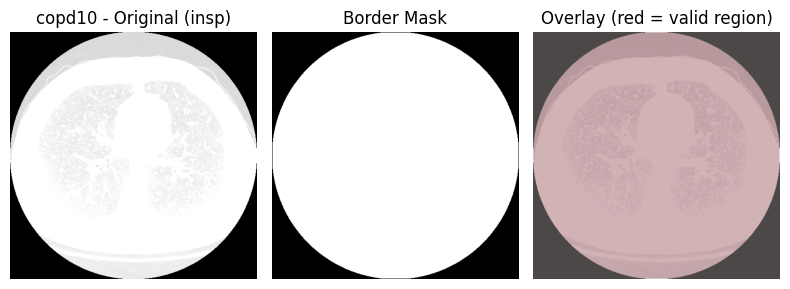

 Visualization saved: copd10_insp_mask_visualization.png


In [42]:
from scipy.ndimage import binary_closing, binary_fill_holes

# CASES = ['copd1', 'copd2', 'copd3','copd4','copd7']#['copd7', 'copd9']#  <------ SELECT CASES HERE <--------

def create_body_mask(volume, hu_threshold=-500):
    """
    Create 3D body mask to remove scanner FOV artifacts (black border)
    
    """
    # 1. Threshold to remove padding/air
    mask = volume > hu_threshold
    
    # 2. 3D morphological cleanup
    # Closing: fills small holes and smooths boundaries
    mask = binary_closing(mask, structure=np.ones((3, 3, 3)))
    
    # Fill holes: ensures the body region is solid
    mask = binary_fill_holes(mask)
    
    return mask.astype(np.uint8)

def generate_border_masks_for_case(case_id):
    """
    Generate border masks for both inhale and exhale phases
 
    """
    print(f"Generating border masks for {case_id}")
    
    case_path = os.path.join(BASE_PATH, case_id)
    
    if not os.path.isdir(case_path):
        print(f"   Case folder not found: {case_path}")
        return
    
    # Define image paths and output mask names
    phases = {
        'insp': {
            'image': os.path.join(case_path, f"{case_id}_iBHCT.nii.gz"),
            'mask': os.path.join(case_path, f"{case_id}_insp_mask.nii.gz")
        },
        'exp': {
            'image': os.path.join(case_path, f"{case_id}_eBHCT.nii.gz"),
            'mask': os.path.join(case_path, f"{case_id}_exp_mask.nii.gz")
        }
    }
    
    for phase_name, paths in phases.items():
        image_path = paths['image']
        mask_path = paths['mask']
        
        # Check if mask already exists
        if os.path.exists(mask_path):
            print(f"  ✓ {phase_name.upper()} mask already exists: {os.path.basename(mask_path)}")
            continue
        
        # Check if image exists
        if not os.path.exists(image_path):
            print(f"  ✗ {phase_name.upper()} image not found: {os.path.basename(image_path)}")
            continue
        
        print(f"\n  Processing {phase_name.upper()} phase...")
        
        # Load image
        image = sitk.ReadImage(image_path)
        volume = sitk.GetArrayFromImage(image).astype(np.float32)
        print(f"    Intensity range: [{volume.min():.1f}, {volume.max():.1f}] HU")
        
        # Create mask
        mask = create_body_mask(volume, hu_threshold=-500)
        
        # Calculate coverage
        coverage = 100 * np.sum(mask) / mask.size
        print(f"    Body coverage: {coverage:.1f}%")
        
        # Save mask
        mask_image = sitk.GetImageFromArray(mask)
        mask_image.CopyInformation(image)  # Copy spacing, origin, direction
        sitk.WriteImage(mask_image, mask_path)
        
        print(f"     Saved mask: {os.path.basename(mask_path)}")
    
    print(f"\n✓ {case_id} border masks complete!")

def visualize_mask_overlay(case_id, phase='insp', slice_idx=None):
    """
    Visualize the border mask overlay on the CT image
    
    Args:
        case_id: Case name
        phase: 'insp' or 'exp'
        slice_idx: Which slice to show (default: middle)
    """
    import matplotlib.pyplot as plt
    
    case_path = os.path.join(BASE_PATH, case_id)
    
    # Load image and mask
    if phase == 'insp':
        image_path = os.path.join(case_path, f"{case_id}_iBHCT.nii.gz")
        mask_path = os.path.join(case_path, f"{case_id}_insp_mask.nii.gz")
    else:
        image_path = os.path.join(case_path, f"{case_id}_eBHCT.nii.gz")
        mask_path = os.path.join(case_path, f"{case_id}_exp_mask.nii.gz")
    
    if not os.path.exists(image_path) or not os.path.exists(mask_path):
        print(f"Image or mask not found for {case_id} ({phase})")
        return
    
    # Load data
    image = sitk.ReadImage(image_path)
    mask = sitk.ReadImage(mask_path)
    
    image_array = sitk.GetArrayFromImage(image)
    mask_array = sitk.GetArrayFromImage(mask)
    
    # Use middle slice if not specified
    if slice_idx is None:
        slice_idx = image_array.shape[0] // 2
    
    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=(8, 5))
    
    # Original image
    axes[0].imshow(image_array[slice_idx], cmap='gray', vmin=-1000, vmax=200)
    axes[0].set_title(f'{case_id} - Original ({phase})')
    axes[0].axis('off')
    
    # Mask
    axes[1].imshow(mask_array[slice_idx], cmap='gray')
    axes[1].set_title('Border Mask')
    axes[1].axis('off')
    
    # Overlay
    axes[2].imshow(image_array[slice_idx], cmap='gray', vmin=-1000, vmax=200)
    axes[2].imshow(mask_array[slice_idx], cmap='Reds', alpha=0.3)
    axes[2].set_title('Overlay (red = valid region)')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.savefig(f'{case_id}_{phase}_mask_visualization.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f" Visualization saved: {case_id}_{phase}_mask_visualization.png")

# MAIN EXECUTION
# Generate masks for all cases
for case_id in CASES:
    generate_border_masks_for_case(case_id)

# Optional: Visualize one example
print("\nGenerating example visualization for copd1...")
try:
    visualize_mask_overlay('copd10', phase='insp')  #### <------------ SELECT CASE HERE (FOR VISUALIZATION) <------- ########
except Exception as e:
    print(f"Visualization failed: {e}")


##### 2.2. INTENSITY NORMALIZATION AND LUNG SEGMENTATION. 
(When completed, check that the resulting masks are ok - in the following section)

In [43]:
from lungmask import LMInferer
''' Creates a mask of the lungs, ~1 min per image'''

# CASES = ['copd1', 'copd2', 'copd3','copd4','copd7']#['copd7', 'copd9']#  <------ SELECT CASES HERE <--------

def apply_border_mask(img_arr, border_mask_path):
    """Sets pixels outside the border mask to -1000 HU (Air)"""
    if border_mask_path and os.path.exists(border_mask_path):
        border_mask = sitk.ReadImage(border_mask_path)
        mask_arr = sitk.GetArrayFromImage(border_mask)
        
        masked_arr = img_arr.copy()
        masked_arr[mask_arr == 0] = -1000 
        valid_region = mask_arr == 1
        return masked_arr, valid_region
    else:
        return img_arr, np.ones_like(img_arr, dtype=bool)

def intensity_correction(img_arr, valid_region=None):
    """Normalize intensity to standard HU range"""
    if valid_region is None:
        valid_region = np.ones_like(img_arr, dtype=bool)

    valid_values = img_arr[valid_region]
    
    if len(valid_values) == 0:
        return img_arr

    p10 = np.percentile(valid_values, 10)
    offset = -850 - p10
    
    img_corrected = img_arr.copy()
    img_corrected[valid_region] = img_arr[valid_region] + offset
    img_corrected = np.clip(img_corrected, -1024, 600)
    
    print(f"      Intensity correction: offset = {offset:.1f} HU")
    
    return img_corrected

def generate_lung_mask(ct_image_path, output_mask_path, output_labels_path):
    """Generate lung mask using R231"""
    if os.path.exists(output_mask_path) and os.path.exists(output_labels_path):
        print(f"    Using existing mask for {os.path.basename(ct_image_path)}")
        return output_mask_path, output_labels_path
    
    print(f"    Generating lung mask for {os.path.basename(ct_image_path)}...")
    
    image = sitk.ReadImage(ct_image_path)
    
    try:
        inferer = LMInferer(modelname='R231', force_cpu=False)
    except:
        inferer = LMInferer(modelname='R231', force_cpu=True)
    
    segmentation_np = inferer.apply(image)
    
    lung_mask = (segmentation_np > 0).astype(np.uint8)
    lung_labels = segmentation_np.astype(np.uint8)
    
    mask_img = sitk.GetImageFromArray(lung_mask)
    mask_img.CopyInformation(image)
    sitk.WriteImage(mask_img, output_mask_path)
    
    labels_img = sitk.GetImageFromArray(lung_labels)
    labels_img.CopyInformation(image)
    sitk.WriteImage(labels_img, output_labels_path)
    
    print(f"      Saved mask and labels")
    
    return output_mask_path, output_labels_path

def preprocess_and_segment(case_id):
    """Apply intensity correction and generate lung masks"""

    print(f"Preprocessing {case_id}")

    # Paths
    raw_fixed = os.path.join(case_id, f"{case_id}_iBHCT.nii.gz")
    raw_moving = os.path.join(case_id, f"{case_id}_eBHCT.nii.gz")
    border_mask_fixed = os.path.join(case_id, f"{case_id}_insp_mask.nii.gz")
    border_mask_moving = os.path.join(case_id, f"{case_id}_exp_mask.nii.gz")
    
    if not os.path.exists(raw_fixed) or not os.path.exists(raw_moving):
        print(f"  ERROR: Images not found")
        return None
    
    # Create masks directory
    if not os.path.exists(MASKS_DIR):
        os.makedirs(MASKS_DIR)
    
    # Process Fixed (Inhale)
    print("\n  Processing Fixed (Inhale)...")
    image_fixed = sitk.ReadImage(raw_fixed)
    img_arr_fixed = sitk.GetArrayFromImage(image_fixed).astype(np.float32)
    
    img_masked_fixed, valid_region_fixed = apply_border_mask(
        img_arr_fixed, 
        border_mask_fixed if os.path.exists(border_mask_fixed) else None
    )
    img_corrected_fixed = intensity_correction(img_masked_fixed, valid_region_fixed)
    
    # Save intensity corrected image
    corrected_fixed_path = os.path.join(MASKS_DIR, f"{case_id}_iBHCT_corrected.nii.gz")
    out_img_fixed = sitk.GetImageFromArray(img_corrected_fixed)
    out_img_fixed.CopyInformation(image_fixed)
    sitk.WriteImage(out_img_fixed, corrected_fixed_path)
    print(f"    Saved: {corrected_fixed_path}")
    
    # Process Moving (Exhale)
    print("\n  Processing Moving (Exhale)...")
    image_moving = sitk.ReadImage(raw_moving)
    img_arr_moving = sitk.GetArrayFromImage(image_moving).astype(np.float32)
    
    img_masked_moving, valid_region_moving = apply_border_mask(
        img_arr_moving,
        border_mask_moving if os.path.exists(border_mask_moving) else None
    )
    img_corrected_moving = intensity_correction(img_masked_moving, valid_region_moving)
    
    corrected_moving_path = os.path.join(MASKS_DIR, f"{case_id}_eBHCT_corrected.nii.gz")
    out_img_moving = sitk.GetImageFromArray(img_corrected_moving)
    out_img_moving.CopyInformation(image_moving)
    sitk.WriteImage(out_img_moving, corrected_moving_path)
    print(f"    Saved: {corrected_moving_path}")
    
    # Generate lung masks
    print("\n  Generating lung masks...")
    mask_fixed = os.path.join(MASKS_DIR, f"{case_id}_iBHCT_lung_mask.nii.gz")
    labels_fixed = os.path.join(MASKS_DIR, f"{case_id}_iBHCT_lung_labels.nii.gz")
    mask_moving = os.path.join(MASKS_DIR, f"{case_id}_eBHCT_lung_mask.nii.gz")
    labels_moving = os.path.join(MASKS_DIR, f"{case_id}_eBHCT_lung_labels.nii.gz")
    
    generate_lung_mask(corrected_fixed_path, mask_fixed, labels_fixed)
    generate_lung_mask(corrected_moving_path, mask_moving, labels_moving)
    
    print(f"\n {case_id} preprocessing complete")
    
    return {
        'corrected_fixed': corrected_fixed_path,
        'corrected_moving': corrected_moving_path,
        'mask_fixed': mask_fixed,
        'mask_moving': mask_moving
    }

# Run preprocessing for all cases
for case_id in CASES:
    if os.path.isdir(case_id):
        preprocess_and_segment(case_id)

Preprocessing copd1

  Processing Fixed (Inhale)...
      Intensity correction: offset = -881.0 HU
    Saved: lung_masks1\copd1_iBHCT_corrected.nii.gz

  Processing Moving (Exhale)...
      Intensity correction: offset = -873.0 HU
    Saved: lung_masks1\copd1_eBHCT_corrected.nii.gz

  Generating lung masks...
    Using existing mask for copd1_iBHCT_corrected.nii.gz
    Using existing mask for copd1_eBHCT_corrected.nii.gz

 copd1 preprocessing complete
Preprocessing copd2

  Processing Fixed (Inhale)...
      Intensity correction: offset = -988.0 HU
    Saved: lung_masks1\copd2_iBHCT_corrected.nii.gz

  Processing Moving (Exhale)...
      Intensity correction: offset = -882.0 HU
    Saved: lung_masks1\copd2_eBHCT_corrected.nii.gz

  Generating lung masks...
    Using existing mask for copd2_iBHCT_corrected.nii.gz
    Using existing mask for copd2_eBHCT_corrected.nii.gz

 copd2 preprocessing complete
Preprocessing copd3

  Processing Fixed (Inhale)...
      Intensity correction: offset =




CREATING OVERVIEW VISUALIZATION


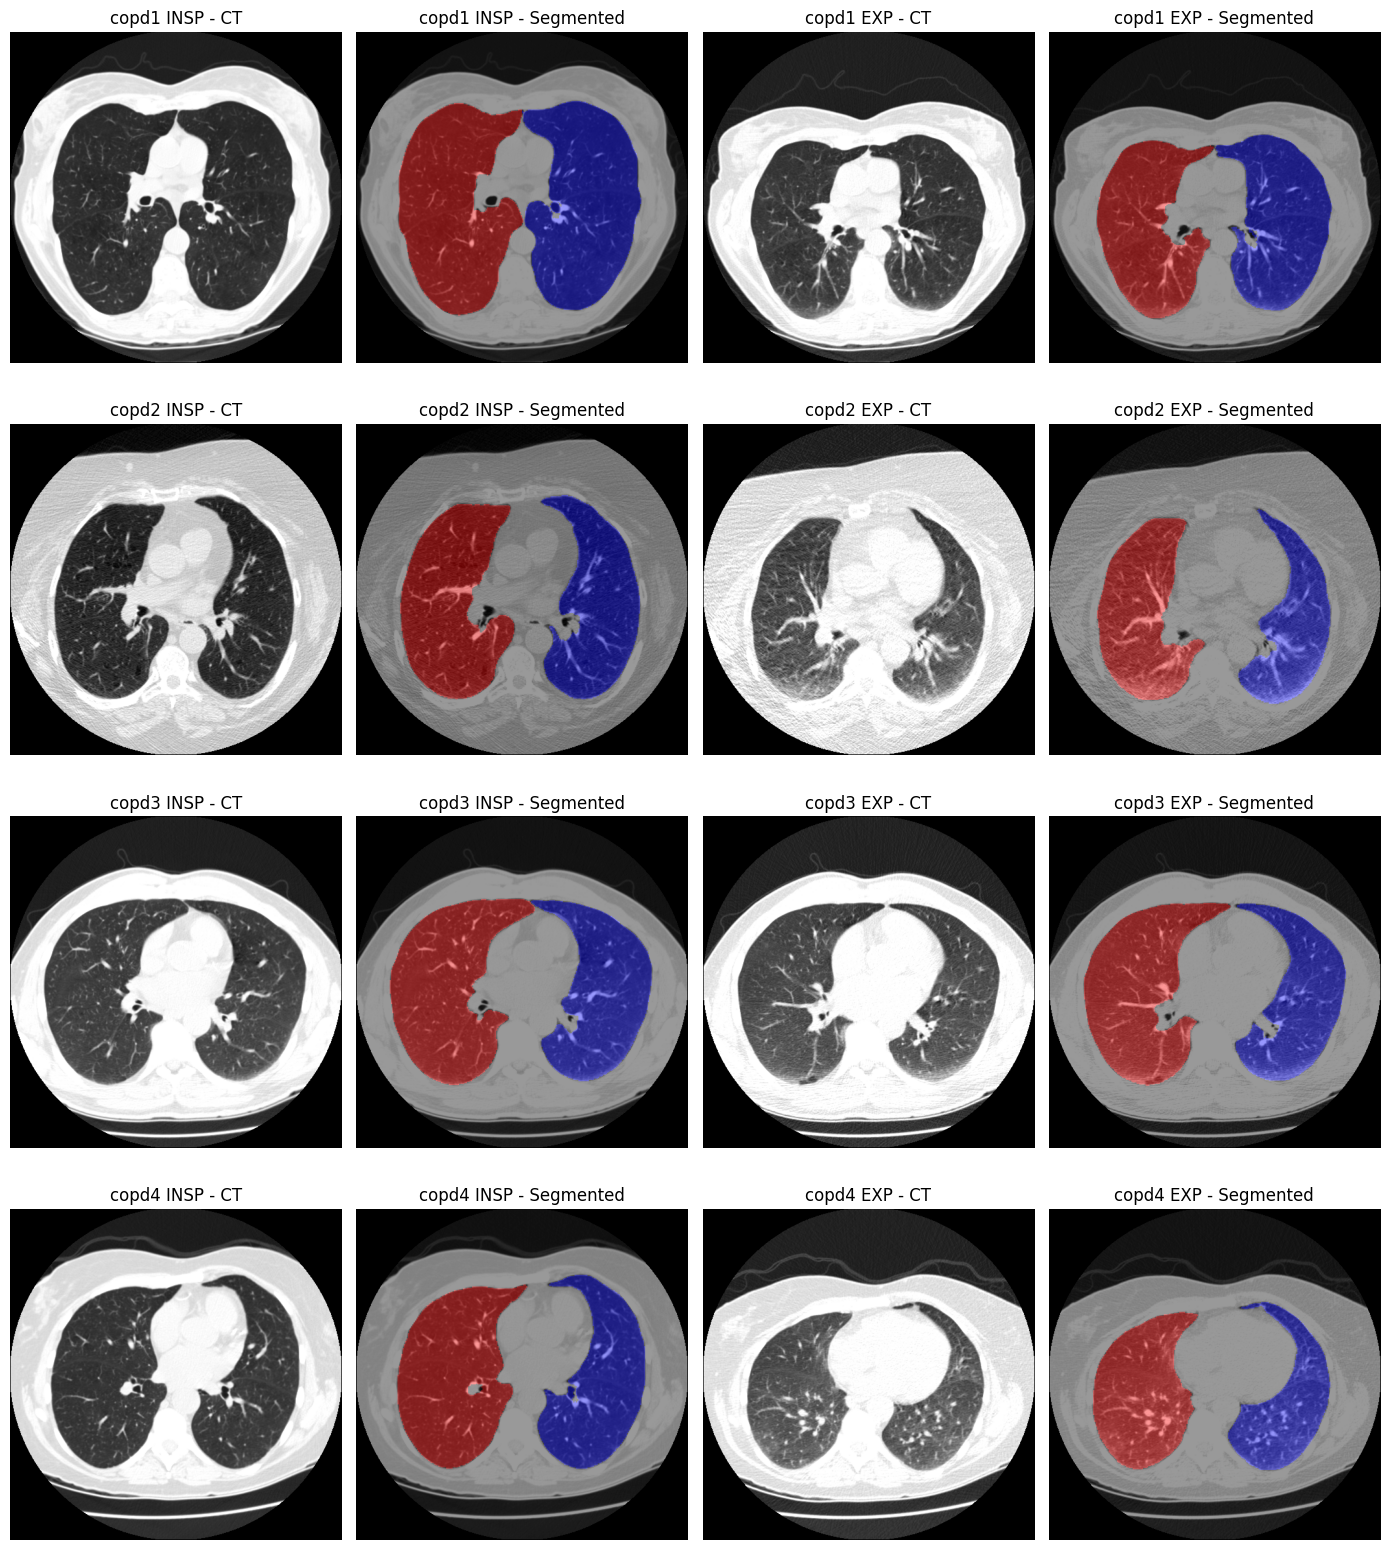

In [33]:
'''TEST: LUNG MASK VISUALIZATION. ~1sec per image '''

import matplotlib.pyplot as plt

# CASES = ['copd1', 'copd2', 'copd3','copd4','copd7']#['copd7', 'copd9']#  <------ SELECT CASES HERE <--------

def visualize_all_cases():
    """Create a grid visualization of all cases"""
    print(f"\n{'='*60}")
    print("CREATING OVERVIEW VISUALIZATION")
    print(f"{'='*60}")
    
    n_cases = len(CASES)
    fig, axes = plt.subplots(n_cases, 4, figsize=(14, 4*n_cases))
    
    if n_cases == 1:
        axes = axes.reshape(1, -1)
    
    for idx, case_id in enumerate(CASES):
        for phase_idx, phase in enumerate(['insp', 'exp']):
            # Determine paths
            if phase == 'insp':
                corrected_path = os.path.join(MASKS_DIR, f"{case_id}_iBHCT_corrected.nii.gz")
                labels_path = os.path.join(MASKS_DIR, f"{case_id}_iBHCT_lung_labels.nii.gz")
            else:
                corrected_path = os.path.join(MASKS_DIR, f"{case_id}_eBHCT_corrected.nii.gz")
                labels_path = os.path.join(MASKS_DIR, f"{case_id}_eBHCT_lung_labels.nii.gz")
            
            col = phase_idx * 2
            
            if os.path.exists(corrected_path) and os.path.exists(labels_path):
                # Load data
                corrected_img = sitk.ReadImage(corrected_path)
                labels_img = sitk.ReadImage(labels_path)
                
                corrected_arr = sitk.GetArrayFromImage(corrected_img)
                labels_arr = sitk.GetArrayFromImage(labels_img)
                
                # Middle slice
                slice_idx = corrected_arr.shape[0] // 2
                
                # Plot CT
                axes[idx, col].imshow(corrected_arr[slice_idx], cmap='gray', vmin=-1000, vmax=200)
                axes[idx, col].set_title(f'{case_id} {phase.upper()} - CT')
                axes[idx, col].axis('off')
                
                # Plot overlay
                axes[idx, col+1].imshow(corrected_arr[slice_idx], cmap='gray', vmin=-1000, vmax=200)
                overlay = np.zeros((*labels_arr[slice_idx].shape, 3))
                overlay[labels_arr[slice_idx] == 1] = [1, 0, 0]
                overlay[labels_arr[slice_idx] == 2] = [0, 0, 1]
                axes[idx, col+1].imshow(overlay, alpha=0.4)
                axes[idx, col+1].set_title(f'{case_id} {phase.upper()} - Segmented')
                axes[idx, col+1].axis('off')
            else:
                axes[idx, col].text(0.5, 0.5, 'Not found', ha='center', va='center')
                axes[idx, col].axis('off')
                axes[idx, col+1].text(0.5, 0.5, 'Not found', ha='center', va='center')
                axes[idx, col+1].axis('off')
    
    plt.tight_layout()
    #plt.savefig('all_cases_lung_segmentation_overview.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    #print(f"✓ Overview saved: all_cases_lung_segmentation_overview.png")

print("\n")
visualize_all_cases()

##### 2.3. CLAHE

In [45]:
'''applies CLAHE to all images and saves them ~1min 30sec per image'''

# # --- CONFIGURATION ---
# CASES = ['copd1', 'copd2', 'copd3','copd4','copd7']#['copd7', 'copd9']#  <------ SELECT CASES HERE <--------

def apply_clahe(img_arr, alpha=0.3, beta=0.3, radius=5):
    """Apply CLAHE enhancement"""
    data_min = -1000
    data_max = 400
    
    clipped = np.clip(img_arr, data_min, data_max)
    normalized = (clipped - data_min) / (data_max - data_min)
    normalized_uint = (normalized * 65535).astype(np.uint16)
    
    temp_sitk = sitk.GetImageFromArray(normalized_uint)
    
    clahe_filter = sitk.AdaptiveHistogramEqualizationImageFilter()
    clahe_filter.SetAlpha(alpha)
    clahe_filter.SetBeta(beta)
    clahe_filter.SetRadius(radius)
    
    enhanced_sitk = clahe_filter.Execute(temp_sitk)
    enhanced_arr = sitk.GetArrayFromImage(enhanced_sitk).astype(np.float32)
    
    enhanced_arr = enhanced_arr / 65535.0
    enhanced_arr = enhanced_arr * (data_max - data_min) + data_min
    
    return enhanced_arr

def apply_clahe_to_case(case_id):
    """Step 3: Apply CLAHE to intensity-corrected images"""
    print(f"CLAHE Enhancement for {case_id}")
    # Create output directory
    if not os.path.exists(PREPROCESSED_DIR):
        os.makedirs(PREPROCESSED_DIR)
    
    # Input paths (intensity corrected images from Step 1)
    corrected_fixed = os.path.join(MASKS_DIR, f"{case_id}_iBHCT_corrected.nii.gz")
    corrected_moving = os.path.join(MASKS_DIR, f"{case_id}_eBHCT_corrected.nii.gz")
    
    # Output paths
    clahe_fixed = os.path.join(PREPROCESSED_DIR, f"{case_id}_iBHCT_clahe.nii.gz")
    clahe_moving = os.path.join(PREPROCESSED_DIR, f"{case_id}_eBHCT_clahe.nii.gz")
    
    if not os.path.exists(corrected_fixed) or not os.path.exists(corrected_moving):
        print(f"  ERROR: Corrected images not found. Run Step 1 first.")
        return None
    
    # Process Fixed
    if os.path.exists(clahe_fixed):
        print(f"  CLAHE fixed image already exists")
    else:
        print(f"  Processing fixed image...")
        image_fixed = sitk.ReadImage(corrected_fixed)
        img_arr_fixed = sitk.GetArrayFromImage(image_fixed).astype(np.float32)
        
        img_clahe_fixed = apply_clahe(img_arr_fixed)
        
        out_fixed = sitk.GetImageFromArray(img_clahe_fixed)
        out_fixed.CopyInformation(image_fixed)
        sitk.WriteImage(out_fixed, clahe_fixed)
        print(f"    Saved: {clahe_fixed}")
    
    # Process Moving
    if os.path.exists(clahe_moving):
        print(f"  CLAHE moving image already exists")
    else:
        print(f"  Processing moving image...")
        image_moving = sitk.ReadImage(corrected_moving)
        img_arr_moving = sitk.GetArrayFromImage(image_moving).astype(np.float32)
        
        img_clahe_moving = apply_clahe(img_arr_moving)
        
        out_moving = sitk.GetImageFromArray(img_clahe_moving)
        out_moving.CopyInformation(image_moving)
        sitk.WriteImage(out_moving, clahe_moving)
        print(f"     Saved: {clahe_moving}")
    
    print(f"\n✓ {case_id} CLAHE enhancement complete!")
    
    return {
        'clahe_fixed': clahe_fixed,
        'clahe_moving': clahe_moving
    }

# Apply CLAHE to all cases
for case_id in CASES:
    if os.path.isdir(case_id):
        apply_clahe_to_case(case_id)

CLAHE Enhancement for copd1
  CLAHE fixed image already exists
  CLAHE moving image already exists

✓ copd1 CLAHE enhancement complete!
CLAHE Enhancement for copd2
  CLAHE fixed image already exists
  CLAHE moving image already exists

✓ copd2 CLAHE enhancement complete!
CLAHE Enhancement for copd3
  CLAHE fixed image already exists
  CLAHE moving image already exists

✓ copd3 CLAHE enhancement complete!
CLAHE Enhancement for copd4
  CLAHE fixed image already exists
  CLAHE moving image already exists

✓ copd4 CLAHE enhancement complete!
CLAHE Enhancement for copd7
  CLAHE fixed image already exists
  CLAHE moving image already exists

✓ copd7 CLAHE enhancement complete!
CLAHE Enhancement for copd10
  CLAHE fixed image already exists
  CLAHE moving image already exists

✓ copd10 CLAHE enhancement complete!


### 3. Registration. 

In [46]:
import subprocess
''' Registration. Select parameters, around 1min 30 sec per image'''
# # --- CONFIGURATION ---
# CASES = ['copd1', 'copd2', 'copd3','copd4','copd7']#['copd7', 'copd9']#  <------ SELECT CASES HERE <--------

def run_registration(case_id, use_masks=True):
    """Step 4: Run Elastix registration"""

    print(f"Registration for {case_id}")
    
    # Parameter files
    affine = "Parameters.Par0008.affine.txt"
    elastic = "Parameters.Par0008.elastic.txt"
    affine1 = "Parameter.affine.txt"
    elastic1 = "Parameter.bsplines.txt"
    affine2= "Par.Affine.txt"
    elastic2="Par.Bsplines.txt"
    
    if not os.path.exists(affine) or not os.path.exists(elastic):
        print("ERROR: Parameter files not found")
        return None
    
    param_list = [affine2, elastic2]    
    
    # Image paths (CLAHE enhanced)
    clahe_fixed = os.path.join(PREPROCESSED_DIR, f"{case_id}_iBHCT_clahe.nii.gz")
    clahe_moving = os.path.join(PREPROCESSED_DIR, f"{case_id}_eBHCT_clahe.nii.gz")
    
    if not os.path.exists(clahe_fixed) or not os.path.exists(clahe_moving):
        print(f"  ERROR: CLAHE images not found. Run Step 3 first.")
        return None
    
    # Mask paths
    mask_fixed = os.path.join(MASKS_DIR, f"{case_id}_iBHCT_lung_mask.nii.gz")
    mask_moving = os.path.join(MASKS_DIR, f"{case_id}_eBHCT_lung_mask.nii.gz")
    
    # Output directory
    out_dir = f"result_{case_id}_clahe"
    if not os.path.exists(out_dir):
        os.makedirs(out_dir)
    
    # Prepare landmark points
    print("\n  Preparing landmark points...")
    raw_pts_path = os.path.join(case_id, f"{case_id}_300_iBH_xyz_r1.txt")
    elastix_input = os.path.join(out_dir, "input_points.txt")
    
    fixed_img = sitk.ReadImage(clahe_fixed)
    
    if os.path.exists(raw_pts_path):
        raw_indices = np.loadtxt(raw_pts_path)
        with open(elastix_input, 'w') as f:
            f.write("point\n")
            f.write(f"{len(raw_indices)}\n")
            for p in raw_indices:
                idx = (int(p[0])-1, int(p[1])-1, int(p[2])-1)
                phys = fixed_img.TransformIndexToPhysicalPoint(idx)
                f.write(f"{phys[0]:.6f} {phys[1]:.6f} {phys[2]:.6f}\n")
        print(f"    Prepared {len(raw_indices)} points")
    
    # Build Elastix command
    print("\n  Running Elastix...")
    elastix_cmd = ["elastix", "-f", clahe_fixed, "-m", clahe_moving]
    
    for param_file in param_list:
        elastix_cmd.extend(["-p", param_file])
    
    elastix_cmd.extend(["-out", out_dir])
    
    # Add masks if requested
    if use_masks and os.path.exists(mask_fixed) and os.path.exists(mask_moving):
        elastix_cmd.extend(["-fMask", mask_fixed, "-mMask", mask_moving])
        print(f"    Mode: WITH lung masks")
    else:
        print(f"    Mode: WITHOUT masks")
    
    # Run registration
    result = subprocess.run(elastix_cmd, capture_output=True, text=True)
    
    if not os.path.exists(os.path.join(out_dir, "TransformParameters.0.txt")):
        print(f"    Registration failed")
        return None
    else:
        print(f"    Registration completed")
    
    # Run Transformix
    print("\n  Transforming points...")
    tp_files = sorted([f for f in os.listdir(out_dir) if f.startswith("TransformParameters")])
    
    if tp_files and os.path.exists(elastix_input):
        tp_file = os.path.join(out_dir, tp_files[-1])
       
        raw_moving = os.path.join(MASKS_DIR, f"{case_id}_eBHCT_corrected.nii.gz")  # Opcional: Registrem la imatge MOVING (exhalació) , no la CLAHE --------
        
        # Comanda actualitzada per incloure la imatge (-in)
        transformix_cmd = ["transformix", "-def", elastix_input, "-in", raw_moving,  "-out", out_dir, "-tp", tp_file]
        #transformix_cmd = ["transformix", "-def", elastix_input,   "-out", out_dir, "-tp", tp_file]
            
        subprocess.run(transformix_cmd, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        print(f"    Points transformed, saved in {out_dir}/outputpoints.txt")
    
    print(f"\n {case_id} registration complete!")
    
    return out_dir

# Run registration for all cases
results_dirs = {}
for case_id in CASES:
    if os.path.isdir(case_id):
        result_dir = run_registration(case_id, use_masks=True)
        if result_dir:
            results_dirs[case_id] = result_dir

Registration for copd1

  Preparing landmark points...
    Prepared 300 points

  Running Elastix...
    Mode: WITH lung masks
    Registration completed

  Transforming points...
    Points transformed, saved in result_copd1_clahe/outputpoints.txt

 copd1 registration complete!
Registration for copd2

  Preparing landmark points...
    Prepared 300 points

  Running Elastix...
    Mode: WITH lung masks
    Registration completed

  Transforming points...
    Points transformed, saved in result_copd2_clahe/outputpoints.txt

 copd2 registration complete!
Registration for copd3

  Preparing landmark points...
    Prepared 300 points

  Running Elastix...
    Mode: WITH lung masks
    Registration completed

  Transforming points...
    Points transformed, saved in result_copd3_clahe/outputpoints.txt

 copd3 registration complete!
Registration for copd4

  Preparing landmark points...
    Prepared 300 points

  Running Elastix...
    Mode: WITH lung masks
    Registration completed

  Tra

### Reformatting Output Files

In [48]:
# --- REFORMAT OUTPUTPOINTS.TXT (Inhale -> Exhale) ---

print("--- PROCESSING OUTPUTPOINTS.TXT ---")

for case_id in CASES:
    print(f"Processing {case_id}...")
    
    # Moving image is needed to convert Physical Points back to Voxel Indices
    moving_img_path = os.path.join(case_id, f"{case_id}_eBHCT.nii.gz")
    
    # Path to the outputpoints.txt file generated by the registration
    result_dir = f"result_{case_id}_clahe"
    output_points_file = os.path.join(result_dir, "outputpoints.txt")
    
    # Output file path
    output_path = os.path.join(case_id, f"{case_id}_300_eBH_xyz_r1_registered.txt")

    # 2. Check files
    if not os.path.exists(moving_img_path):
        print(f"  [Skipping] Moving image not found: {moving_img_path}")
        continue
    if not os.path.exists(output_points_file):
        print(f"  [Skipping] outputpoints.txt not found: {output_points_file}")
        continue

    # 3. Load Moving Image (to define geometry for index conversion)
    moving_img = sitk.ReadImage(moving_img_path)
    
    # 4. Parse outputpoints.txt and Transform
    transformed_points = []
    
    with open(output_points_file, 'r') as f:
        for line in f:
            # Look for the "OutputPoint" field in each line
            if "OutputPoint" in line:
                # Split by semicolon to isolate fields
                parts = line.split(';')
                for part in parts:
                    if "OutputPoint" in part:
                        # Extract the numbers inside [ ... ]
                        # Format is typically: OutputPoint = [ x y z ]
                        raw_values = part.split('=')[1].replace('[', '').replace(']', '').strip()
                        physical_coords = [float(x) for x in raw_values.split()]
                        
                        # Convert Physical Point -> Continuous Index (0-based)
                        idx_moving = moving_img.TransformPhysicalPointToContinuousIndex(physical_coords)
                        
                        # Convert to 1-based index (r1 format) to match input format
                        p_out = (idx_moving[0] + 1, idx_moving[1] + 1, idx_moving[2] + 1)
                        transformed_points.append(p_out)

    # 5. Save to .txt file
    if transformed_points:
        np.savetxt(output_path, transformed_points, fmt='%.4f', delimiter='\t')
        print(f"  [Saved] {len(transformed_points)} points saved to: {output_path}")
    else:
        print(f"  [Warning] No points extracted from {output_points_file}")

--- PROCESSING OUTPUTPOINTS.TXT ---
Processing copd1...
  [Saved] 300 points saved to: copd1\copd1_300_eBH_xyz_r1_registered.txt
Processing copd2...
  [Saved] 300 points saved to: copd2\copd2_300_eBH_xyz_r1_registered.txt
Processing copd3...
  [Saved] 300 points saved to: copd3\copd3_300_eBH_xyz_r1_registered.txt
Processing copd4...
  [Saved] 300 points saved to: copd4\copd4_300_eBH_xyz_r1_registered.txt
Processing copd7...
  [Saved] 300 points saved to: copd7\copd7_300_eBH_xyz_r1_registered.txt
Processing copd10...
  [Saved] 300 points saved to: copd10\copd10_300_eBH_xyz_r1_registered.txt


### 4. TRE Computation (initial version)

In [50]:
import re

#CASES = ['copd1', 'copd2', 'copd3', 'copd4','copd7']#['copd7', 'copd9']#   <-------- SELECT CASES HERE <------------------

def calculate_tre(case_id, result_dir):
    """Step 5: Calculate TRE for a case"""
    print(f"-{case_id}")
    
    # Paths
    gt_pts_path = os.path.join(case_id, f"{case_id}_300_eBH_xyz_r1.txt")
    result_file = os.path.join(result_dir, "outputpoints.txt")
    clahe_moving = os.path.join(PREPROCESSED_DIR, f"{case_id}_eBHCT_clahe.nii.gz")
    
    if not os.path.exists(result_file):
        print(f"  ERROR: outputpoints.txt not found")
        return None
    
    if not os.path.exists(gt_pts_path):
        print(f"  ERROR: Ground truth points not found")
        return None
    
    # Parse transformed points
    transformed_points = []
    with open(result_file, 'r') as f:
        for line in f:
            match = re.search(r'OutputPoint = \[ (.*?) \]', line)
            if match:
                transformed_points.append(list(map(float, match.group(1).split())))
    
    # Load ground truth
    moving_img = sitk.ReadImage(clahe_moving)
    gt_indices = np.loadtxt(gt_pts_path)
    gt_phys = []
    for p in gt_indices:
        idx = (int(p[0])-1, int(p[1])-1, int(p[2])-1)
        gt_phys.append(moving_img.TransformIndexToPhysicalPoint(idx))
    
    gt_phys = np.array(gt_phys)
    transformed_points = np.array(transformed_points)
    
    if len(gt_phys) != len(transformed_points):
        print(f"  ERROR: Point count mismatch")
        return None
    
    # Calculate distances
    dist = np.sqrt(np.sum((transformed_points - gt_phys)**2, axis=1))
    
    mean_tre = np.mean(dist)
    std_tre = np.std(dist)
    median_tre = np.median(dist)
    min_tre = np.min(dist)
    max_tre = np.max(dist)
    
    print(f"  Mean TRE:   {mean_tre:.4f} mm")
    print(f"  Std TRE:    {std_tre:.4f} mm")
    print(f"  Median TRE: {median_tre:.4f} mm")
    print(f"  Min TRE:    {min_tre:.4f} mm")
    print(f"  Max TRE:    {max_tre:.4f} mm")
    print(f"  {'='*50}")
    
    # Save statistics
    stats_file = os.path.join(result_dir, "TRE_statistics.txt")
    with open(stats_file, 'w') as f:
        f.write(f"Case: {case_id}\n")
        f.write(f"Mean TRE:   {mean_tre:.4f} mm\n")
        f.write(f"Std TRE:    {std_tre:.4f} mm\n")
        f.write(f"Median TRE: {median_tre:.4f} mm\n")
        f.write(f"Min TRE:    {min_tre:.4f} mm\n")
        f.write(f"Max TRE:    {max_tre:.4f} mm\n")
    
    return {
        'case': case_id,
        'mean_tre': mean_tre,
        'std_tre': std_tre,
        'median_tre': median_tre,
        'min_tre': min_tre,
        'max_tre': max_tre
    }

# Calculate TRE for all cases
all_results = []
for case_id in CASES:
    result_dir = f"result_{case_id}_clahe"
    if os.path.isdir(case_id) and os.path.isdir(result_dir):
        result = calculate_tre(case_id, result_dir)
        if result:
            all_results.append(result)

# Print summary
if all_results:
    print("FINAL SUMMARY")
    for res in all_results:
        print(f"{res['case']}: Mean={res['mean_tre']:.4f} mm, Median={res['median_tre']:.4f} mm")
    
    overall_mean = np.mean([r['mean_tre'] for r in all_results])
    overall_std = np.std([r['std_tre'] for r in all_results])
    print(f"{'='*60}")
    print(f"Overall Mean TRE: {overall_mean:.4f} mm")
    print(f"STD: {overall_std:.4f} mm")
    print(f"{'='*60}")

-copd1
  Mean TRE:   1.1853 mm
  Std TRE:    0.8263 mm
  Median TRE: 1.0026 mm
  Min TRE:    0.1636 mm
  Max TRE:    7.0211 mm
-copd2
  Mean TRE:   3.0784 mm
  Std TRE:    4.0485 mm
  Median TRE: 1.5836 mm
  Min TRE:    0.1789 mm
  Max TRE:    23.3686 mm
-copd3
  Mean TRE:   1.2680 mm
  Std TRE:    0.7783 mm
  Median TRE: 1.1178 mm
  Min TRE:    0.1911 mm
  Max TRE:    6.0075 mm
-copd4
  Mean TRE:   1.4595 mm
  Std TRE:    1.1157 mm
  Median TRE: 1.1657 mm
  Min TRE:    0.1434 mm
  Max TRE:    9.9804 mm
-copd7
  Mean TRE:   1.3406 mm
  Std TRE:    1.0601 mm
  Median TRE: 1.0993 mm
  Min TRE:    0.1442 mm
  Max TRE:    10.6748 mm
-copd10
  Mean TRE:   1.4054 mm
  Std TRE:    0.9190 mm
  Median TRE: 1.2147 mm
  Min TRE:    0.2031 mm
  Max TRE:    7.4514 mm
FINAL SUMMARY
copd1: Mean=1.1853 mm, Median=1.0026 mm
copd2: Mean=3.0784 mm, Median=1.5836 mm
copd3: Mean=1.2680 mm, Median=1.1178 mm
copd4: Mean=1.4595 mm, Median=1.1657 mm
copd7: Mean=1.3406 mm, Median=1.0993 mm
copd10: Mean=1.4054 m

##### TRE Computation (saved txt files)

In [ ]:
# --- CALCULATE TRE, CHECK THAT IT IS THE SAME AS BEFORE (THE FILES WERE CORRECTLY SAVED)

print("--- TRE CALCULATION REPORT --")

overall_means = []

for case_id in CASES:
    # 1. Define Paths
    reg_path = os.path.join(case_id, f"{case_id}_300_eBH_xyz_r1_registered.txt")
    gt_path = os.path.join(case_id, f"{case_id}_300_eBH_xyz_r1.txt")
    
    # We need the reference image to convert Indices -> Physical Coordinates (mm)
    # Using the Exhale image (moving image) as the reference for these points
    ref_img_path = os.path.join(case_id, f"{case_id}_eBHCT.nii.gz")
    
    # 2. Validation
    if not (os.path.exists(reg_path) and os.path.exists(gt_path) and os.path.exists(ref_img_path)):
        print(f"[{case_id}] Skipping: Files missing.")
        continue
        
    # 3. Load Data
    p_reg_idx = np.loadtxt(reg_path) # Registered Indices (1-based)
    p_gt_idx = np.loadtxt(gt_path)   # Ground Truth Indices (1-based)
    ref_img = sitk.ReadImage(ref_img_path)
    
    # 4. Convert Indices to Physical Points (mm)
    # Note: The indices are 1-based (r1), so subtract 1 for 0-based ITK
    
    p_reg_mm = []
    p_gt_mm = []
    
    for p in p_reg_idx:
        # (r1 -> r0) -> Physical
        phy = ref_img.TransformContinuousIndexToPhysicalPoint((p[0]-1, p[1]-1, p[2]-1))
        p_reg_mm.append(phy)
        
    for p in p_gt_idx:
        # (r1 -> r0) -> Physical
        phy = ref_img.TransformContinuousIndexToPhysicalPoint((p[0]-1, p[1]-1, p[2]-1))
        p_gt_mm.append(phy)
        
    p_reg_mm = np.array(p_reg_mm)
    p_gt_mm = np.array(p_gt_mm)
    
    # 5. Compute Euclidean Distances (TRE in mm)
    diff = p_reg_mm - p_gt_mm
    tre_values = np.linalg.norm(diff, axis=1)
    
    # 6. Statistics
    mean_tre = np.mean(tre_values)
    std_tre = np.std(tre_values)
    median_tre = np.median(tre_values)
    min_tre = np.min(tre_values)
    max_tre = np.max(tre_values)
    
    overall_means.append(mean_tre)
    
    print(f"[{case_id}] Statistics:")
    print(f"  Mean TRE:   {mean_tre:.4f} mm (+/- {std_tre:.4f})")
    print(f"  Median TRE: {median_tre:.4f} mm")
    print(f"  Range:      {min_tre:.4f} - {max_tre:.4f} mm")

# 7. Overall Summary
if overall_means:
    print("-" * 40)
    print(f"OVERALL MEAN TRE (All Cases): {np.mean(overall_means):.4f} mm")
    print("-" * 40)

--- TRE CALCULATION REPORT --
[copd1] Statistics:
  Mean TRE:   1.1853 mm (+/- 0.8263)
  Median TRE: 1.0026 mm
  Range:      0.1636 - 7.0211 mm
[copd2] Statistics:
  Mean TRE:   3.0784 mm (+/- 4.0485)
  Median TRE: 1.5837 mm
  Range:      0.1789 - 23.3685 mm
[copd3] Statistics:
  Mean TRE:   1.2680 mm (+/- 0.7783)
  Median TRE: 1.1178 mm
  Range:      0.1911 - 6.0075 mm
[copd4] Statistics:
  Mean TRE:   1.4595 mm (+/- 1.1157)
  Median TRE: 1.1657 mm
  Range:      0.1434 - 9.9804 mm
[copd7] Statistics:
  Mean TRE:   1.3406 mm (+/- 1.0601)
  Median TRE: 1.0993 mm
  Range:      0.1443 - 10.6748 mm
[copd10] Statistics:
  Mean TRE:   1.4054 mm (+/- 0.9190)
  Median TRE: 1.2148 mm
  Range:      0.2031 - 7.4514 mm
----------------------------------------
OVERALL MEAN TRE (All Cases): 1.6229 mm
----------------------------------------
